In [ ]:
import numpy as np

from beta_evidence_field import (OccupancyField,
                                 OccupancyObservation,
                                 OccupancyPrior,
                                 OccupancyQuery)

from tools.plotting import (configure_plots,
                            plot_beta_states,
                            plot_query_progression)

configure_plots()

## Evidence Concentration and Uncertainty

The expected occupancy probability does not uniquely describe the state of an occupancy estimate. Balanced occupied and free-space evidence can produce the same mean occupancy across a wide range of evidence concentrations.

The following comparison holds the expected occupancy at approximately $0.5$ while increasing the accumulated evidence, illustrating how concentration distinguishes weakly and strongly supported estimates.

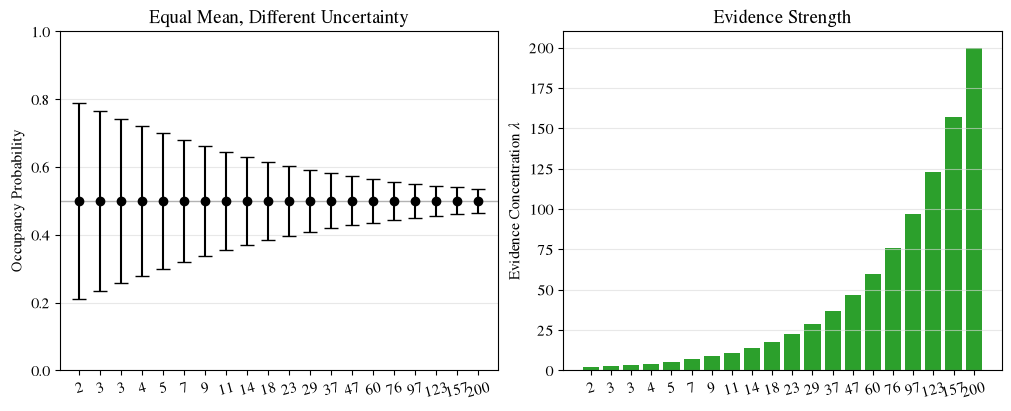

In [ ]:
concentrations = np.logspace(np.log10(2.0), np.log10(200.0), 20)

queries = [OccupancyQuery(alpha   = concentration / 2.0,
                          beta    = concentration / 2.0,
                          support = concentration > 2.0) for concentration in concentrations]

labels = [f"{concentration:.0f}" for concentration in concentrations]

p = plot_beta_states(queries = queries, labels  = labels)

## Consistent Evidence

Repeated consistent observations reinforce the estimated state of a location. Occupied evidence should drive the expected occupancy toward $1$, while free-space evidence should drive it toward $0$.

In both cases, accumulating evidence increases concentration and reduces the variance of the estimated occupancy probability.

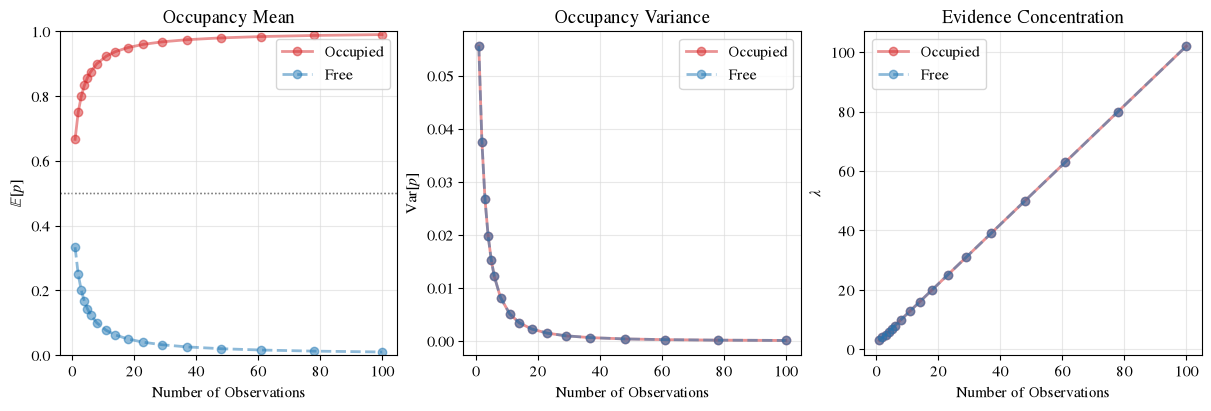

In [ ]:
observation = OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                   direction = np.array([1.0, 0.0]),
                                   range     = 3.0,
                                   returned  = True,
                                   time      = 0.0)

occupied_point = observation.endpoint
free_point     = observation.origin + 0.5*observation.range*observation.direction

counts = np.unique(np.logspace(np.log10(1), np.log10(100), 20).astype(int))

occupied_queries = []
free_queries     = []


for count in counts:

    field = OccupancyField.from_yaml("../config/example_2d_config.yaml")

    field.add([OccupancyObservation(origin          = observation.origin,
                                    direction       = observation.direction,
                                    range           = observation.range,
                                    returned        = observation.returned,
                                    time            = observation.time,
                                    evidence_weight = count)])

    occupied_queries.append(field.query(points = occupied_point,
                                        time   = observation.time))

    free_queries.append(field.query(points = free_point,
                                    time   = observation.time))


p = plot_query_progression(counts = counts,
                           queries = {"Occupied" : occupied_queries,
                                      "Free"     : free_queries})

## Conflicting Evidence

A location may receive both occupied and free\-space evidence as observations accumulate. Here, observations are sampled stochastically between the two evidence types with equal probability.

The expected occupancy therefore fluctuates around $0.5$, while evidence concentration continues to increase and occupancy variance decreases as more observations are accumulated.

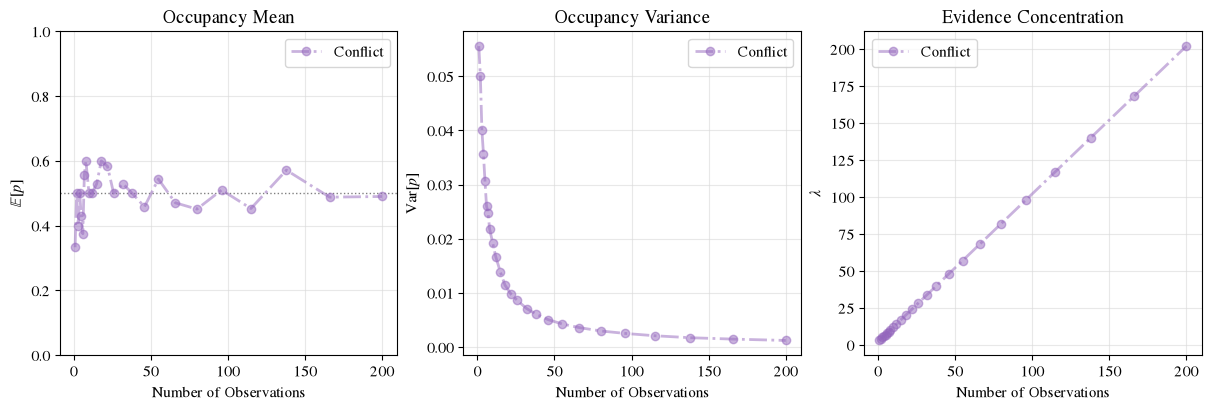

In [ ]:
rng = np.random.default_rng(42)

conflict_point = np.array([0.0, 0.0])

occupied_observation = OccupancyObservation(origin    = np.array([-3.0, 0.0]),
                                            direction = np.array([1.0, 0.0]),
                                            range     = 3.0,
                                            returned  = True,
                                            time      = 0.0)

free_observation = OccupancyObservation(origin    = np.array([0.0, -2.0]),
                                        direction = np.array([0.0, 1.0]),
                                        range     = 4.0,
                                        returned  = False,
                                        time      = 0.0)


counts = np.unique(np.logspace(np.log10(1), np.log10(200), 30).astype(int))

conflict_queries = []


for count in counts:

    field    = OccupancyField.from_yaml("../config/example_2d_config.yaml")
    occupied = rng.random(count) < 0.5

    observations = [OccupancyObservation(origin    = (occupied_observation.origin
                                                      if state else free_observation.origin),
                                         direction = (occupied_observation.direction
                                                      if state else free_observation.direction),
                                         range     = (occupied_observation.range
                                                      if state else free_observation.range),
                                         returned  = bool(state),
                                         time      = 0.0)
                    for state in occupied]

    field.add(observations)
    conflict_queries.append(field.query(points = conflict_point,
                                        time   = 0.0))


p = plot_query_progression(counts = counts,
                           queries = {"Conflict" : conflict_queries})

## Unobserved and Conflicting Evidence

An occupancy probability near $0.5$ can represent fundamentally different states.

An unobserved location remains near $0.5$ because little evidence is available. A location receiving substantial conflicting evidence may produce a similar occupancy estimate despite being strongly supported by observations.

Evidence concentration and occupancy variance preserve the distinction between these cases.

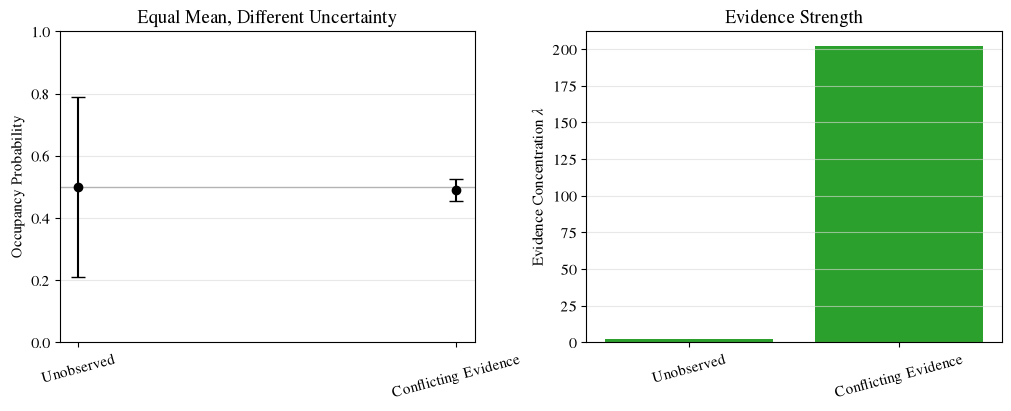

In [ ]:
field            = OccupancyField.from_yaml("../config/example_2d_config.yaml")

unobserved_query = field.query(points = conflict_point,
                               time   = 0.0)

conflicted_query = conflict_queries[-1]


p = plot_beta_states(queries = [unobserved_query,
                                conflicted_query],
                     labels = ["Unobserved",
                               "Conflicting Evidence"])

## Interpretation

The Beta evidence representation separates **occupancy belief** from **evidence strength**.

Consistent occupied or free\-space observations drive the expected occupancy toward their respective states while increasing concentration and reducing variance. Conflicting observations can instead maintain an expected occupancy near $0.5$ despite substantial accumulated evidence.

Consequently, an occupancy probability near $0.5$ does not necessarily indicate insufficient information: it may represent either weak evidence or strong disagreement between observations.
